# Pemodelan dan Simulasi Dinamika Konsentrasi CO₂ di Dalam Ruang Kelas
**Mata kuliah:** Pemodelan Sistem Dinamik  |  **Nama / NIM:** ................

Model satu-zona *well-mixed* (neraca massa CO₂):

$$V\frac{dC}{dt}=n\,g\,10^{6}-Q\,(C-C_{out})$$

- $C$ = konsentrasi CO₂ dalam kelas (ppm), $C_{out}$ = CO₂ udara luar (420 ppm)
- $V$ = volume kelas (168 m³), $n$ = jumlah orang (31), $g$ = emisi CO₂ per orang (5×10⁻⁶ m³/s)
- $Q$ = laju ventilasi (m³/menit), $\lambda = Q/V = ACH/60$ (1/menit)

Notebook ini menduplikasi struktur materi *Dynamic System Modelling* (tangki cairan → kelas, kran inlet → okupansi, kran outlet → jendela/ventilasi).

In [1]:
# Jalankan sekali di Google Colab
!pip install gekko -q

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

## Program 1: Kasus 1 – Ventilasi tertutup (analog tangki dengan outlet tertutup) (ODEINT)

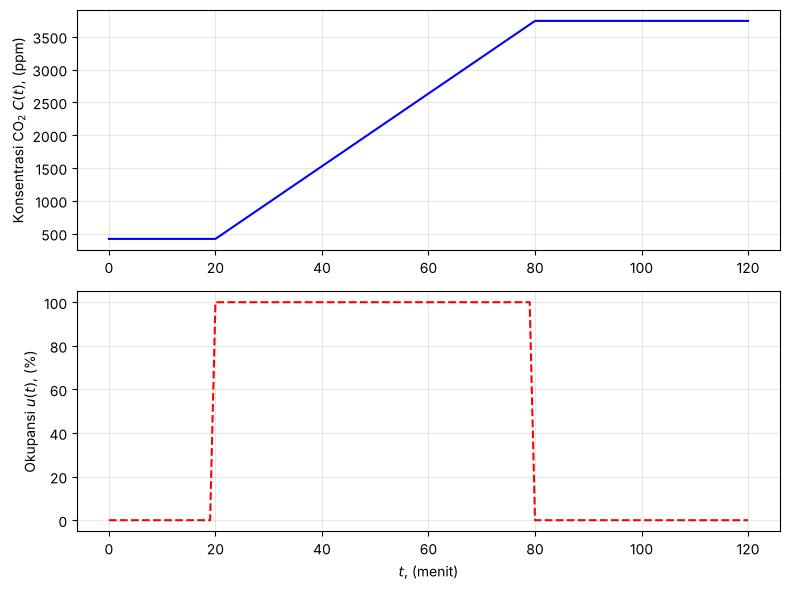

C maksimum = 3741.4 ppm


In [2]:
# Program 1: CO2 di ruang kelas, ventilasi TERTUTUP (ODEINT)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# ---- model ruang kelas: dC/dt = c*u / V  ----
def kelas(C, t, c, u):
    V = 168.0                 # volume ruang kelas (m^3) = 8 x 7 x 3
    dCdt = (c / V) * u        # laju kenaikan CO2 (ppm/menit)
    return dCdt

# waktu simulasi 0-120 menit, setiap 1 menit
ts = np.linspace(0, 120, 121)

# koefisien generasi CO2 (ppm.m^3/menit per % okupansi)
# c = n * g * 1e6 * 60 / 100 = 31 * 5e-6 * 1e6 * 60 / 100 = 93
c = 93.0
u = np.zeros(121)             # u = okupansi kelas (%)
u[20:80] = 100.0              # kelas terisi penuh antara menit 20 s.d. 80

C0 = 420.0                    # kondisi awal = CO2 udara luar (ppm)
z = np.zeros(121)
z[0] = C0

# simulasi dengan ODEINT, langkah demi langkah (cara yang sama seperti contoh)
for i in range(120):
    okupansi = u[i]           # u ditahan konstan selama interval [t_i, t_i+1]
    y = odeint(kelas, C0, [0, 1], args=(c, okupansi))
    C0 = y[-1][0]             # ambil titik terakhir
    z[i + 1] = C0

# plot hasil
os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(ts, z, 'b-')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.grid(alpha=0.3)
plt.subplot(2, 1, 2)
plt.plot(ts, u, 'r--')
plt.ylabel(r'Okupansi $u(t)$, (%)')
plt.xlabel(r'$t$, (menit)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/gambar_01_tertutup.png', dpi=150)
plt.show()
print('C maksimum = %.1f ppm' % z.max())


## Program 2: Kasus 1 – Ventilasi tertutup (GEKKO)

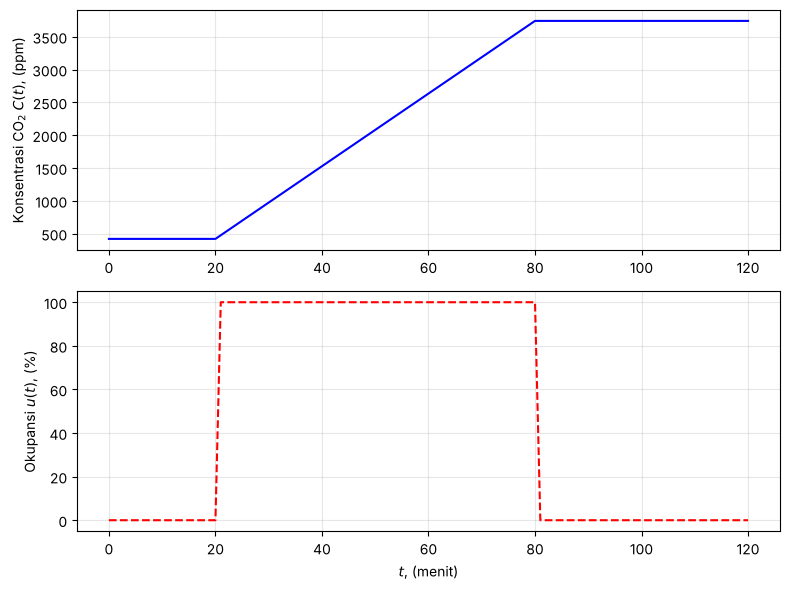

C maksimum = 3741.4 ppm


In [3]:
# Program 2: CO2 di ruang kelas, ventilasi TERTUTUP (GEKKO)
import os
import numpy as np
from gekko import GEKKO
import matplotlib.pyplot as plt

V = 168.0                          # volume ruang kelas (m^3)
c = 93.0                           # koefisien generasi CO2 (ppm.m^3/menit per %)

m = GEKKO(remote=False)            # buat model GEKKO
m.time = np.linspace(0, 120, 121)  # titik waktu (menit)

ustep = np.zeros(121)
ustep[21:81] = 100.0               # okupansi 100% antara menit 20-80
                                   # (GEKKO memakai nilai input di akhir interval -> indeks digeser 1)
u = m.Param(value=ustep)           # input okupansi (%)

C = m.Var(420.0)                   # konsentrasi CO2 awal (ppm)
m.Equation(C.dt() == (c / V) * u)  # persamaan diferensial

m.options.IMODE = 4                # simulasi dinamik
m.solve(disp=False)

os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(m.time, C.value, 'b-')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.grid(alpha=0.3)
plt.subplot(2, 1, 2)
plt.plot(m.time, ustep, 'r--')
plt.ylabel(r'Okupansi $u(t)$, (%)')
plt.xlabel(r'$t$, (menit)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/gambar_01b_tertutup_gekko.png', dpi=150)
plt.show()
print('C maksimum = %.1f ppm' % max(C.value))


## Program 3: Kasus 2 – Ventilasi dikendalikan jendela (analog kran inlet & outlet) (ODEINT)

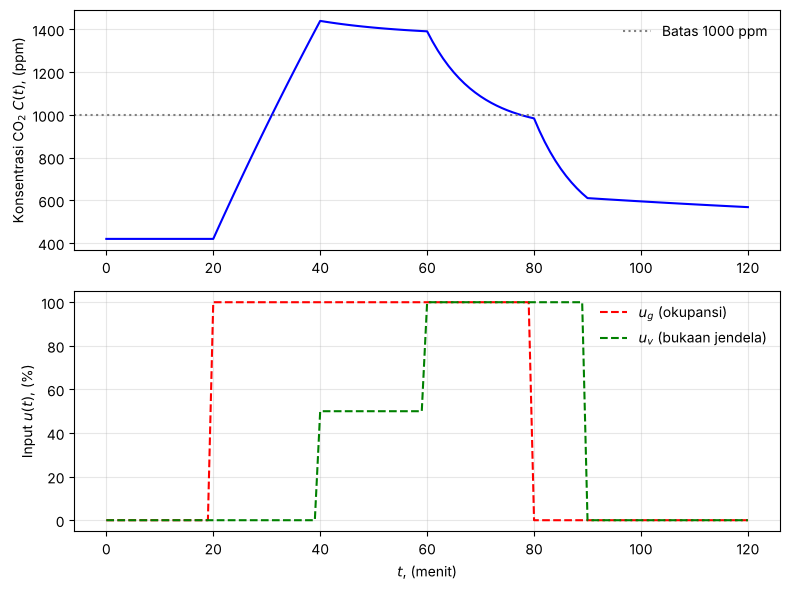

C maksimum = 1439.8 ppm pada t = 40 menit


In [4]:
# Program 3: CO2 di ruang kelas, ventilasi DIKENDALIKAN oleh jendela (ODEINT)
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# ---- model: V dC/dt = c_g*u_g - (Q0 + c_v*u_v)*(C - C_out) ----
def kelas(C, t, cg, cv, ug, uv):
    V = 168.0                       # volume ruang kelas (m^3)
    Q0 = 1.4                        # infiltrasi dasar = 0.5 ACH (m^3/menit)
    C_out = 420.0                   # CO2 udara luar (ppm)
    Q = Q0 + cv * uv                # laju ventilasi total (m^3/menit)
    dCdt = (cg * ug - Q * (C - C_out)) / V
    return dCdt

ts = np.linspace(0, 120, 121)       # 0-120 menit, setiap 1 menit

cg = 93.0                           # koefisien generasi (ppm.m^3/menit per %)
cv = 0.168                          # koefisien ventilasi (m^3/menit per % bukaan)

ug = np.zeros(121)                  # ug = okupansi (%)
ug[20:80] = 100.0                   # kelas terisi menit 20-80
uv = np.zeros(121)                  # uv = bukaan jendela (%)
uv[40:60] = 50.0                    # jendela dibuka 50% menit 40-60
uv[60:90] = 100.0                   # jendela dibuka 100% menit 60-90

C0 = 420.0
z = np.zeros(121)
z[0] = C0

# input ditahan konstan (zero-order hold) selama interval [t_i, t_i+1]
for i in range(120):
    y = odeint(kelas, C0, [0, 1], args=(cg, cv, ug[i], uv[i]))
    C0 = y[-1][0]
    z[i + 1] = C0

os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(ts, z, 'b-')
plt.axhline(1000, color='gray', ls=':', label='Batas 1000 ppm')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.subplot(2, 1, 2)
plt.plot(ts, ug, 'r--', label=r'$u_g$ (okupansi)')
plt.plot(ts, uv, 'g--', label=r'$u_v$ (bukaan jendela)')
plt.ylabel(r'Input $u(t)$, (%)')
plt.xlabel(r'$t$, (menit)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/gambar_02_dikendalikan.png', dpi=150)
plt.show()
print('C maksimum = %.1f ppm pada t = %.0f menit' % (z.max(), ts[z.argmax()]))


## Program 4: Kasus 2 – Ventilasi dikendalikan jendela (GEKKO)

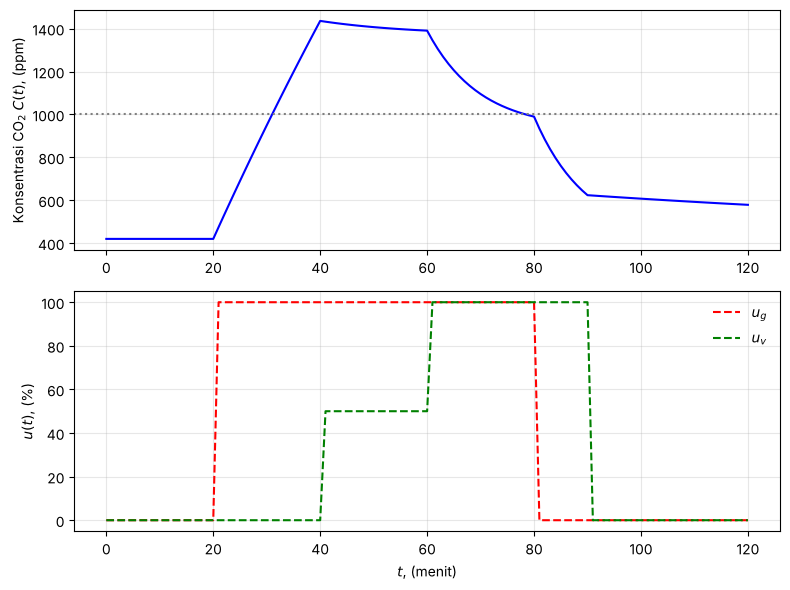

C maksimum = 1435.9 ppm


In [5]:
# Program 4: CO2 di ruang kelas, ventilasi DIKENDALIKAN (GEKKO)
import os
import numpy as np
from gekko import GEKKO
import matplotlib.pyplot as plt

V, Q0, C_out = 168.0, 1.4, 420.0
cg, cv = 93.0, 0.168

m = GEKKO(remote=False)
m.time = np.linspace(0, 120, 121)

# GEKKO memakai nilai input di akhir interval -> indeks digeser 1
ug_arr = np.zeros(121); ug_arr[21:81] = 100.0
uv_arr = np.zeros(121); uv_arr[41:61] = 50.0; uv_arr[61:91] = 100.0
ug = m.Param(value=ug_arr)
uv = m.Param(value=uv_arr)

C = m.Var(420.0)
m.Equation(V * C.dt() == cg * ug - (Q0 + cv * uv) * (C - C_out))

m.options.IMODE = 4
m.solve(disp=False)

os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(m.time, C.value, 'b-')
plt.axhline(1000, color='gray', ls=':')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.grid(alpha=0.3)
plt.subplot(2, 1, 2)
plt.plot(m.time, ug_arr, 'r--', label=r'$u_g$')
plt.plot(m.time, uv_arr, 'g--', label=r'$u_v$')
plt.xlabel(r'$t$, (menit)'); plt.ylabel(r'$u(t)$, (%)')
plt.legend(frameon=False); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('figures/gambar_02b_dikendalikan_gekko.png', dpi=150)
plt.show()
print('C maksimum = %.1f ppm' % max(C.value))


## Program 5: Kasus 3 – Pengaruh laju ventilasi ACH (analog variasi k) (ODEINT)

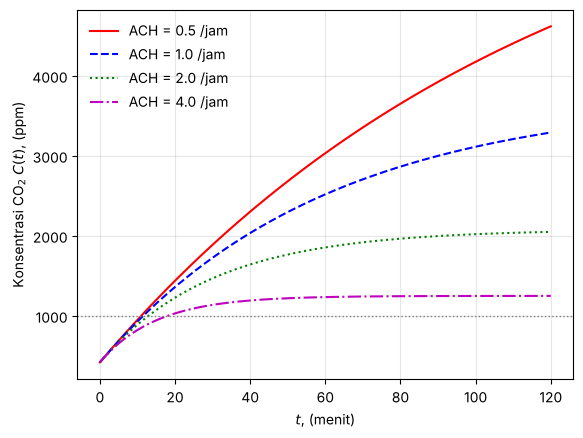

ACH 0.5 -> C(120 menit) = 4619 ppm
ACH 1.0 -> C(120 menit) = 3292 ppm
ACH 2.0 -> C(120 menit) = 2050 ppm
ACH 4.0 -> C(120 menit) = 1250 ppm


In [6]:
# Program 5: Pengaruh laju ventilasi (ACH) terhadap CO2 (ODEINT, args)
import os
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# fungsi model: dC/dt = G + lam*(C_out - C), lam = ACH/60 (1/menit)
def model(C, t, ach):
    V = 168.0
    n, g = 31, 5.0e-6                 # jumlah orang, emisi CO2 (m^3/s/orang)
    C_out = 420.0
    G = n * g * 1e6 * 60 / V          # generasi (ppm/menit)
    lam = ach / 60.0                  # laju pertukaran udara (1/menit)
    return G + lam * (C_out - C)

C0 = 420.0
t = np.linspace(0, 120, 241)

hasil = {}
for ach in [0.5, 1.0, 2.0, 4.0]:
    hasil[ach] = odeint(model, C0, t, args=(ach,))

os.makedirs('figures', exist_ok=True)
gaya = {0.5: 'r-', 1.0: 'b--', 2.0: 'g:', 4.0: 'm-.'}
for ach, y in hasil.items():
    plt.plot(t, y, gaya[ach], label='ACH = %.1f /jam' % ach)
plt.axhline(1000, color='gray', ls=':', lw=1)
plt.xlabel(r'$t$, (menit)')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.savefig('figures/gambar_03_variasi_ach.png', dpi=150)
plt.show()
for ach, y in hasil.items():
    print('ACH %.1f -> C(120 menit) = %.0f ppm' % (ach, y[-1][0]))


## Program 6: Kasus 3 – Pengaruh laju ventilasi ACH (GEKKO)

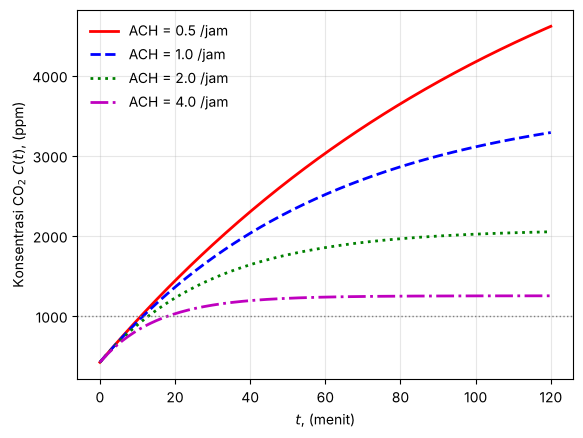

In [7]:
# Program 6: Pengaruh laju ventilasi (ACH) terhadap CO2 (GEKKO)
import os
import numpy as np
from gekko import GEKKO
import matplotlib.pyplot as plt

V, C_out = 168.0, 420.0
G = 31 * 5.0e-6 * 1e6 * 60 / V           # generasi CO2 (ppm/menit)

m = GEKKO(remote=False)
m.time = np.linspace(0, 120, 241)
ach = m.Param()                          # laju ventilasi (parameter yang diubah-ubah)
C = m.Var(420.0)
m.Equation(C.dt() == G + (ach / 60.0) * (C_out - C))

m.options.IMODE = 4
m.options.TIME_SHIFT = 0

os.makedirs('figures', exist_ok=True)
for nilai, gaya in zip([0.5, 1.0, 2.0, 4.0], ['r-', 'b--', 'g:', 'm-.']):
    ach.value = nilai
    m.solve(disp=False)
    plt.plot(m.time, C.value, gaya, linewidth=2, label='ACH = %.1f /jam' % nilai)

plt.axhline(1000, color='gray', ls=':', lw=1)
plt.xlabel(r'$t$, (menit)')
plt.ylabel(r'Konsentrasi CO$_2$ $C(t)$, (ppm)')
plt.legend(frameon=False); plt.grid(alpha=0.3)
plt.savefig('figures/gambar_03b_variasi_ach_gekko.png', dpi=150)
plt.show()


## Program 7: Kasus 4 – Respon step okupansi (persamaan orde satu) (ODEINT)

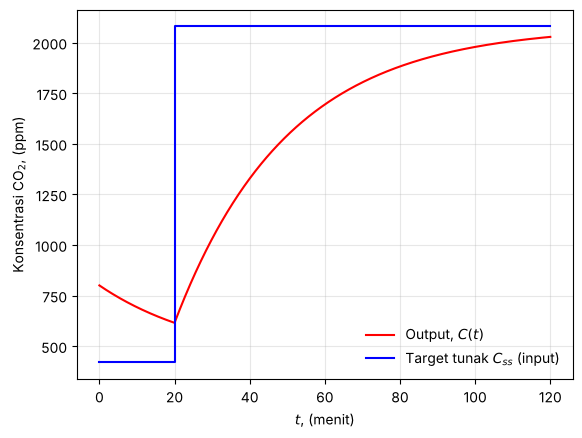

C(120) = 2028.4 ppm


In [8]:
# Program 7: Respon CO2 terhadap input step okupansi (orde satu, ODEINT)
import os
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# tau * dC/dt = -(C - C_out) + dC_ss * s(t)
def model(C, t):
    tau = 30.0                       # konstanta waktu = V/Q = 1/lambda (menit), ACH = 2
    C_out = 420.0
    dC_ss = 1660.7                   # kenaikan CO2 keadaan tunak: G/lambda (ppm)
    # step okupansi: kelas kosong sampai t = 20, lalu terisi 31 orang
    s = 0.0 if t < 20.0 else 1.0
    return (-(C - C_out) + dC_ss * s) / tau

C0 = 800.0                           # sisa CO2 dari pelajaran sebelumnya (ppm)
t = np.linspace(0, 120, 1201)
C = odeint(model, C0, t, tcrit=[20.0])   # tcrit: titik diskontinu input

os.makedirs('figures', exist_ok=True)
plt.plot(t, C, 'r-', label=r'Output, $C(t)$')
plt.plot([0, 20, 20, 120], [420, 420, 2080.7, 2080.7], 'b-', label=r'Target tunak $C_{ss}$ (input)')
plt.xlabel(r'$t$, (menit)')
plt.ylabel(r'Konsentrasi CO$_2$, (ppm)')
plt.legend(loc='best', frameon=False)
plt.grid(alpha=0.3)
plt.savefig('figures/gambar_04_step.png', dpi=150)
plt.show()
print('C(120) = %.1f ppm' % C[-1][0])


## Program 8: Kasus 4 – Respon step okupansi (GEKKO)

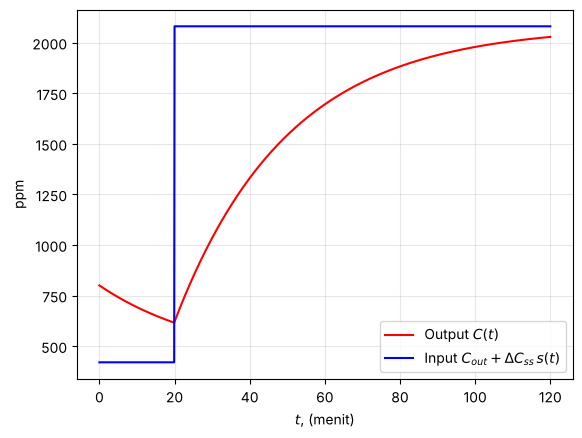

In [9]:
# Program 8: Respon CO2 terhadap input step okupansi (GEKKO)
import os
import numpy as np
from gekko import GEKKO
import matplotlib.pyplot as plt

m = GEKKO(remote=False)
m.time = np.linspace(0, 120, 1201)

ustep = np.zeros(1201)
ustep[200:] = 1660.7                 # step pada t = 20 menit (indeks 200)
u = m.Param(value=ustep)

C = m.Var(800.0)
m.Equation(30 * C.dt() == -(C - 420.0) + u)

m.options.IMODE = 4
m.solve(disp=False)

os.makedirs('figures', exist_ok=True)
plt.plot(m.time, C.value, 'r-', label=r'Output $C(t)$')
plt.plot(m.time, ustep + 420, 'b-', label=r'Input $C_{out}+\Delta C_{ss}\,s(t)$')
plt.xlabel(r'$t$, (menit)'); plt.ylabel('ppm')
plt.legend(loc='best'); plt.grid(alpha=0.3)
plt.savefig('figures/gambar_04b_step_gekko.png', dpi=150)
plt.show()


## Program 9: Kasus 5 – Skenario utama sehari sekolah dengan strategi ventilasi u (ODEINT)

Skenario                   C maks    >1000 ppm    >1500 ppm  C rata2 kelas
Tertutup (u=0)               5386        229 m        219 m         3476
Bukaan kecil (u=0.1)         3215        228 m        216 m         2414
Bukaan sedang (u=0.3)        1843        205 m        142 m         1569
Terbuka penuh (u=1)           931          0 m          0 m          883


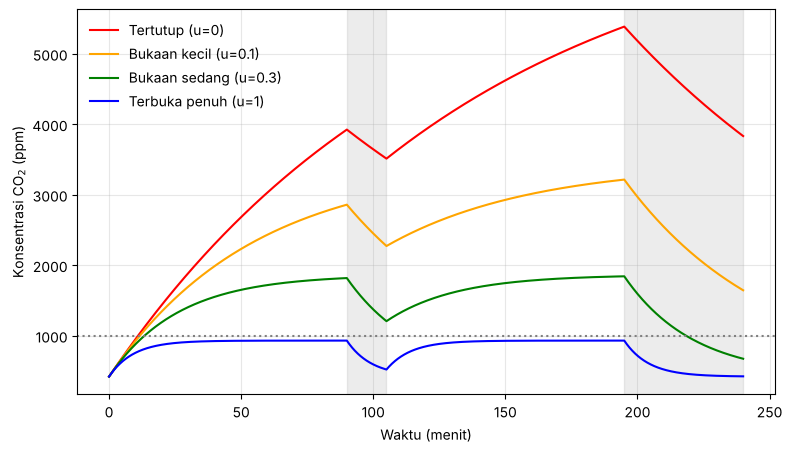

In [10]:
# Program 9: Skenario utama - strategi ventilasi u pada kelas selama 240 menit (ODEINT)
import os
import numpy as np
from scipy.integrate import odeint
import matplotlib.pyplot as plt

V = 168.0                 # volume kelas (m^3)
C_out = 420.0             # CO2 udara luar (ppm)
g = 5.0e-6                # emisi CO2 per orang (m^3/s)
ACH0 = 0.5                # infiltrasi dasar (1/jam)
ACH_MAX = 6.0             # tambahan ACH saat jendela/pintu terbuka penuh (u = 1)

def jumlah_orang(t):
    # kelas 1: 0-90 menit | istirahat: 90-105 | kelas 2: 105-195 | kosong: > 195
    if t < 90 or (105 <= t < 195):
        return 31
    return 0

# model: dC/dt = n*g*1e6*60/V + lam*(C_out - C), lam = (ACH0 + ACH_MAX*u)/60
def kelas(C, t, u):
    n = jumlah_orang(t)
    G = n * g * 1e6 * 60 / V
    lam = (ACH0 + ACH_MAX * u) / 60.0
    return G + lam * (C_out - C)

t = np.linspace(0, 240, 2401)
skenario = {0.0: 'Tertutup (u=0)', 0.1: 'Bukaan kecil (u=0.1)',
            0.3: 'Bukaan sedang (u=0.3)', 1.0: 'Terbuka penuh (u=1)'}
warna = {0.0: 'r', 0.1: 'orange', 0.3: 'g', 1.0: 'b'}

os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(9, 5))
print('%-24s %8s %12s %12s %14s' % ('Skenario', 'C maks', '>1000 ppm', '>1500 ppm', 'C rata2 kelas'))
ada = np.array([jumlah_orang(x) > 0 for x in t])   # penanda saat kelas terisi
for u, nama in skenario.items():
    C = odeint(kelas, C_out, t, args=(u,), tcrit=[90, 105, 195], hmax=0.5)[:, 0]
    plt.plot(t, C, color=warna[u], label=nama)
    print('%-24s %8.0f %10.0f m %10.0f m %12.0f' % (nama, C.max(), (C > 1000).sum() * 0.1,
          (C > 1500).sum() * 0.1, C[ada].mean()))
plt.axhline(1000, color='gray', ls=':')
plt.axvspan(90, 105, color='gray', alpha=0.15)
plt.axvspan(195, 240, color='gray', alpha=0.15)
plt.xlabel('Waktu (menit)')
plt.ylabel(r'Konsentrasi CO$_2$ (ppm)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.savefig('figures/gambar_05_skenario_utama.png', dpi=150)
plt.show()


## Program 10: Kasus 5 – Skenario utama sehari sekolah (GEKKO)

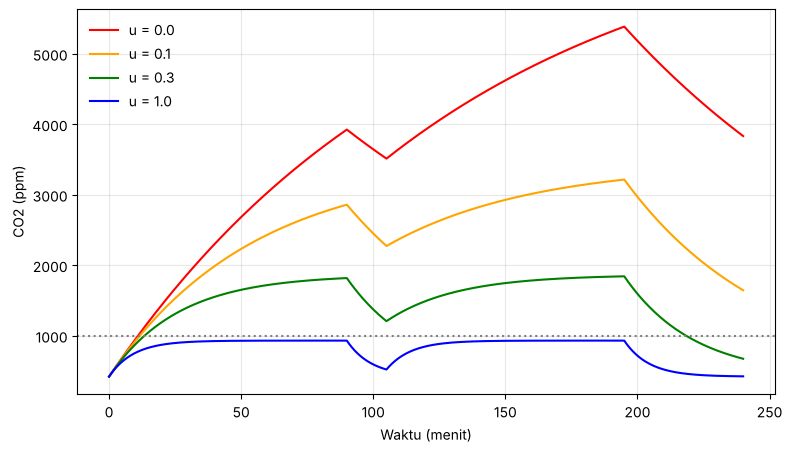

In [11]:
# Program 10: Skenario utama (GEKKO) - strategi u divariasikan dengan FV
import os
import numpy as np
from gekko import GEKKO
import matplotlib.pyplot as plt

V, C_out, g = 168.0, 420.0, 5.0e-6
ACH0, ACH_MAX = 0.5, 6.0

m = GEKKO(remote=False)
t = np.linspace(0, 240, 481)
m.time = t

n_arr = np.where((t < 90) | ((t >= 105) & (t < 195)), 31.0, 0.0)
n = m.Param(value=n_arr)             # jumlah orang di kelas (berubah terhadap waktu)
u = m.FV(0.0)                        # strategi ventilasi (0-1)

C = m.Var(C_out)
G = n * g * 1e6 * 60 / V
lam = (ACH0 + ACH_MAX * u) / 60.0
m.Equation(C.dt() == G + lam * (C_out - C))

m.options.IMODE = 4
m.options.TIME_SHIFT = 0
m.options.NODES = 3

os.makedirs('figures', exist_ok=True)
plt.figure(figsize=(9, 5))
for uu, w in zip([0.0, 0.1, 0.3, 1.0], ['r', 'orange', 'g', 'b']):
    u.value = uu
    m.solve(disp=False)
    plt.plot(m.time, C.value, color=w, label='u = %.1f' % uu)
plt.axhline(1000, color='gray', ls=':')
plt.xlabel('Waktu (menit)'); plt.ylabel('CO2 (ppm)')
plt.legend(frameon=False); plt.grid(alpha=0.3)
plt.savefig('figures/gambar_05b_skenario_gekko.png', dpi=150)
plt.show()


## Program 11: Verifikasi – Perhitungan manual (Euler) vs analitik vs ODEINT (Python)

In [12]:
# Program 11: Verifikasi perhitungan manual (metode Euler) vs solusi analitik vs ODEINT
import numpy as np
from scipy.integrate import odeint

# Kasus: kelas terisi 31 orang, ACH = 2 /jam, C(0) = 420 ppm
V, n, g, C_out, ach = 168.0, 31, 5.0e-6, 420.0, 2.0
G = n * g * 1e6 * 60 / V            # generasi (ppm/menit)      -> 55.357
lam = ach / 60.0                    # laju ventilasi (1/menit)  -> 0.03333
tau = 1 / lam                       # konstanta waktu (menit)   -> 30
Css = C_out + G / lam               # keadaan tunak (ppm)       -> 2080.7
print('G = %.3f ppm/menit, lambda = %.5f /menit, tau = %.1f menit, Css = %.1f ppm' % (G, lam, tau, Css))

dt = 5.0                            # langkah Euler (menit)
t = np.arange(0, 60 + dt, dt)
C_euler = np.zeros_like(t); C_euler[0] = 420.0
for k in range(len(t) - 1):
    dCdt = G + lam * (C_out - C_euler[k])
    C_euler[k + 1] = C_euler[k] + dt * dCdt

C_an = Css - (Css - 420.0) * np.exp(-t / tau)              # solusi analitik
C_ode = odeint(lambda C, tt: G + lam * (C_out - C), 420.0, t)[:, 0]

print('%5s %10s %10s %10s %10s %10s' % ('t', 'Euler', 'Analitik', 'ODEINT', 'Err Euler', 'Err %'))
for k in range(len(t)):
    e = C_euler[k] - C_an[k]
    print('%5.0f %10.1f %10.1f %10.1f %10.1f %10.2f' % (t[k], C_euler[k], C_an[k], C_ode[k], e, 100 * e / C_an[k]))

# waktu mencapai 1000 ppm (analitik)
t1000 = -tau * np.log((Css - 1000) / (Css - 420))
print('Waktu mencapai 1000 ppm = %.1f menit' % t1000)


G = 55.357 ppm/menit, lambda = 0.03333 /menit, tau = 30.0 menit, Css = 2080.7 ppm
    t      Euler   Analitik     ODEINT  Err Euler      Err %
    0      420.0      420.0      420.0        0.0       0.00
    5      696.8      674.9      674.9       21.8       3.24
   10      927.4      890.8      890.8       36.7       4.12
   15     1119.7     1073.4     1073.4       46.2       4.31
   20     1279.8     1228.1     1228.1       51.8       4.21
   25     1413.3     1359.0     1359.0       54.3       4.00
   30     1524.5     1469.8     1469.8       54.8       3.73
   35     1617.2     1563.6     1563.6       53.7       3.43
   40     1694.5     1643.0     1643.0       51.5       3.14
   45     1758.9     1710.2     1710.2       48.7       2.85
   50     1812.5     1767.0     1767.0       45.5       2.57
   55     1857.2     1815.2     1815.2       42.0       2.31
   60     1894.5     1856.0     1856.0       38.5       2.07
Waktu mencapai 1000 ppm = 12.9 menit


## Kesimpulan
1. Tanpa ventilasi, CO₂ naik linear (≈55 ppm/menit) – sama seperti tinggi cairan pada tangki dengan outlet tertutup.
2. Dengan ventilasi, CO₂ menuju keadaan tunak $C_{ss}=C_{out}+nG/Q$ dengan konstanta waktu $\tau=V/Q$.
3. Membuka jendela/pintu (u=1) menjaga CO₂ < 1000 ppm, sedangkan kelas tertutup mencapai > 5000 ppm.